# Q1 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


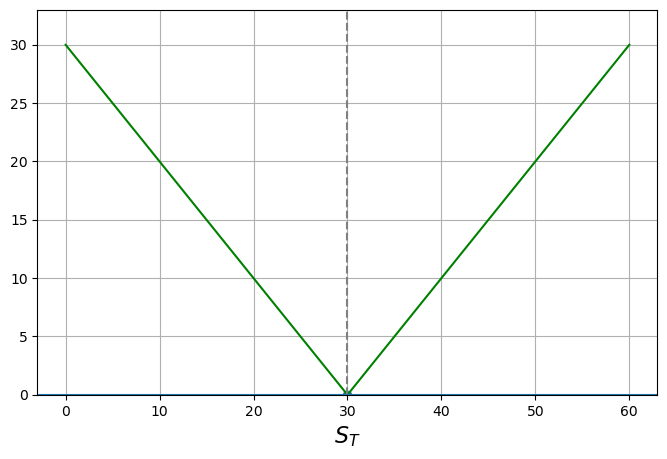

In [4]:
# Absolut Payoff 
S = np.linspace(0, 60, 200)
K = 30

payoff_abs = np.maximum(S - K, 0) + np.maximum(K - S, 0)

plt.figure(figsize=(8, 5))
plt.plot(S, payoff_abs, linewidth=1.5, color='g')
plt.axvline(K, linestyle="--", color='grey')
plt.axhline(0)
plt.scatter([K], [0])
plt.xlabel("$S_T$", fontsize=16)
#plt.title("Absolut Payoff")
plt.grid(True)
plt.xlim(-3, 63)
plt.ylim(0, payoff_abs.max() * 1.1)
plt.savefig('report/Plots/1.pdf', bbox_inches='tight', dpi=1000)
plt.show()


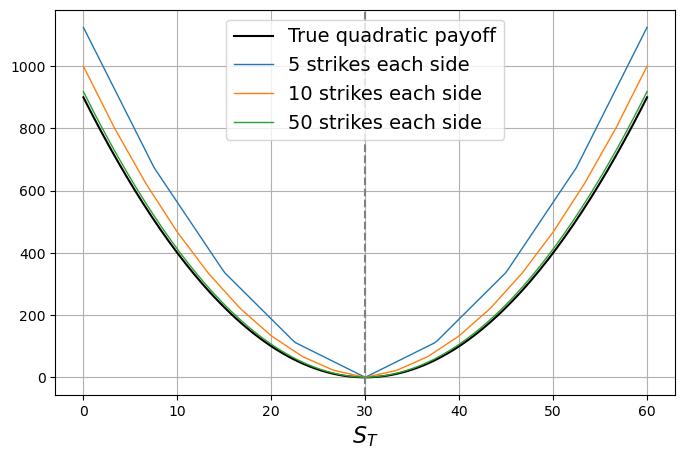

In [5]:
target = (S - K)**2

def quadratic_replication_calls_puts(S, K, n_strikes, K_min=0, K_max=60):
    K_puts  = np.linspace(K_min, K, n_strikes)
    K_calls = np.linspace(K, K_max, n_strikes)

    dK_put  = K_puts[1] - K_puts[0]
    dK_call = K_calls[1] - K_calls[0]

    payoff = np.zeros_like(S)

    # puts below K
    for K in K_puts:
        payoff += dK_put * np.maximum(K - S, 0)

    # calls above K
    for K in K_calls:
        payoff += dK_call * np.maximum(S - K, 0)

    return 2 * payoff

plt.figure(figsize=(8,5))

plt.plot(S, target, 'k', linewidth=1.5, label="True quadratic payoff")

for n in [5, 10, 50]:
    approx = quadratic_replication_calls_puts(S, K, n)
    plt.plot(S, approx, linewidth=1, label=f"{n} strikes each side")

plt.axvline(K, linestyle="--", color='grey')
plt.xlabel("$S_T$", fontsize=16)
#plt.title("Quadratic Payoff Replication with Calls and Puts")
plt.grid(True)
plt.legend(fontsize=14)
plt.savefig('report/Plots/2.pdf', bbox_inches='tight', dpi=1000)
plt.show()

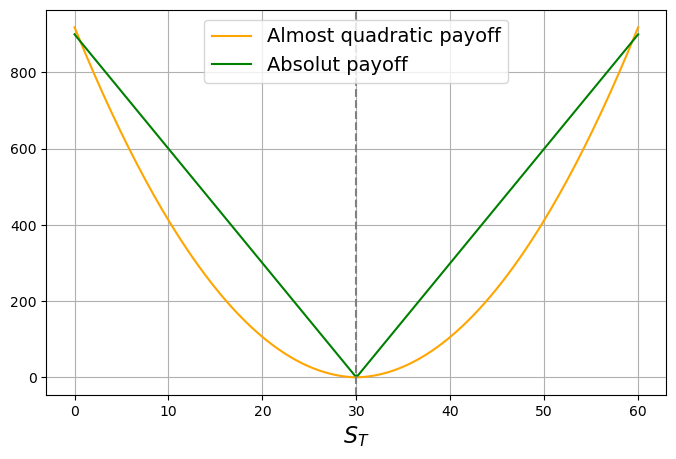

In [6]:
plt.figure(figsize=(8,5))

plt.plot(S, approx, 'orange', linewidth=1.5, label="Almost quadratic payoff") 
plt.plot(S, payoff_abs*30, linewidth=1.5, color='g', label="Absolut payoff")

plt.axvline(K, linestyle="--", color='grey')
plt.xlabel("$S_T$", fontsize=16)
#plt.title("Comparaison Absolut $&$ Quadratic with 100 contracts")
plt.grid(True)
plt.legend(fontsize =14)
plt.savefig('report/Plots/3.pdf', bbox_inches='tight', dpi=1000)
plt.show() #3

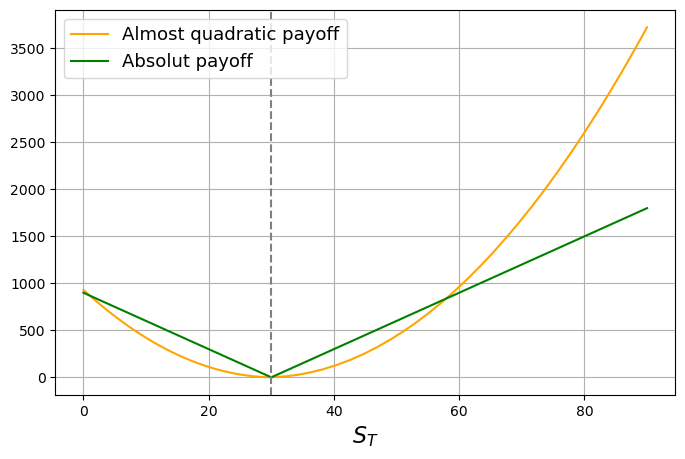

In [7]:
# what if we don't limit ourself to 200 for S_T ? 
S_2 = np.linspace(0, 90, 400)
payoff_abs_2 = 30 * (np.maximum(S_2 - K, 0) + np.maximum(K - S_2, 0)) # contracts
payoff_Quad_1 = quadratic_replication_calls_puts(S_2,K, 30, 0, 90)

plt.figure(figsize=(8,5))
plt.plot(S_2, payoff_Quad_1, 'orange', linewidth=1.5, label="Almost quadratic payoff") #using 100 contracts mimicking Quadratic
plt.plot(S_2, payoff_abs_2, linewidth=1.5, color='g', label="Absolut payoff")

plt.axvline(K, linestyle="--", color='grey')
plt.xlabel("$S_T$", fontsize=16)
plt.legend(fontsize=13)
#plt.title("Comparaison Absolut $&$ Quadratic with 100 calls")
plt.grid(True)
plt.savefig('report/Plots/4.pdf', bbox_inches='tight', dpi=1000)
plt.show()

# Q2 

In [8]:
#ASSUMPTIONS
S0 = 30
K = 30
r = 0.04
sigma = 0.15
T = 1
n =1000000

In [9]:
rng = np.random.default_rng()


In [10]:
def absolut_MC(S0, K, rf, sigma, T, n, rng):
    Z = rng.standard_normal(n)
    S_t = S0 * np.exp((rf - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    payoffs = np.abs((S_t - K))
    price = np.exp(-rf * T) * np.mean(payoffs)
    return price, S_t
V_abs, S_t1= absolut_MC(S0, K, r, sigma, T, n, rng)
print(V_abs, S_t1.mean())

3.6416916400096007 31.224736953510135


In [11]:
def quadratic_MC(S0, K, rf, sigma, T, n, rng):
    Z = rng.standard_normal(n)
    S_t = S0 * np.exp((rf - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    payoffs = (S_t - K) ** 2
    price = np.exp(-rf * T) * np.mean(payoffs)
    return price, S_t
V_quad, S_t2= quadratic_MC(S0, K, r, sigma, T, n, rng)
print(V_quad, S_t2.mean())

22.8081823100525 31.221977317882548


In [12]:
def absolute_NI(S0, K, r, sigma, T, L=6, N=1000000):
    u = np.linspace(-L, L, N)
    du = u[1] - u[0]
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * u)
    # Absolute payoff
    payoff = np.abs(ST - K)
    # Risk-neutral expectation (Riemann sum)
    price = np.exp(-r * T) * np.sum(payoff * norm.pdf(u) * du)
    return price
V0_a = absolute_NI(S0, K, r, sigma, T)
print(V0_a)

3.640842926621295


In [13]:
def quadratic_NI(S0, K, r, sigma, T,L=6, N=1000000):
    u = np.linspace(-L, L, N)
    du = u[1] - u[0]
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * u)
    payoff = (ST - K)**2
    # Risk-neutral pricing via Riemann sum
    price = np.exp(-r * T) * np.sum(payoff * norm.pdf(u) * du)
    return price, ST
V0_q, S_T_quad = quadratic_NI(S0, K, r, sigma, T)
print(V0_q)

22.755505797031002


In [14]:
def quadratic_analytic(S0, K, r, sigma, T):
    ES_T = S0 * np.exp(r * T)
    ES_T2 = S0**2 * np.exp((2*r + sigma**2) * T)
    V0 = np.exp(-r * T) * (ES_T2 - 2*K*ES_T + K**2)
    return V0
V0_analytic = quadratic_analytic(S0, K, r, sigma, T)
print(V0_analytic)

22.75550826316441


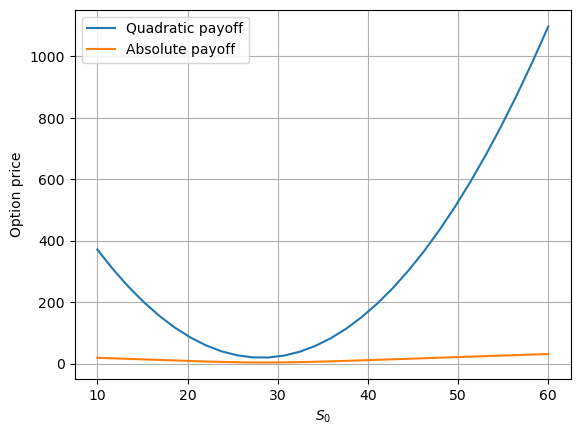

In [15]:
# sensitivity Analysis 
S0_grid = np.linspace(10, 60, 30)

V_quad_S0 = [quadratic_analytic(s, K, r, sigma, T) for s in S0_grid]
V_abs_S0  = [absolute_NI(s, K, r, sigma, T) for s in S0_grid]

plt.plot(S0_grid, V_quad_S0, label="Quadratic payoff")
plt.plot(S0_grid, V_abs_S0, label="Absolute payoff")
plt.xlabel("$S_0$")
plt.ylabel("Option price")
plt.legend()
plt.grid()
plt.savefig('report/Plots/5.pdf', bbox_inches='tight', dpi=1000)
plt.show()

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
/var/folders/qr/j8df0yz964s42s7h8zvb7j_c0000gn/T/ipykernel_86193/1599206525.py:8: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel("$\sigma$")


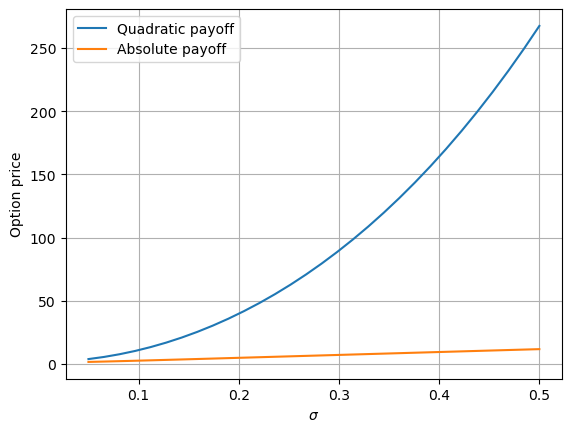

In [16]:
sigma_grid = np.linspace(0.05, 0.50, 30)

V_quad_sigma = [quadratic_analytic(S0, K, r, s, T) for s in sigma_grid]
V_abs_sigma  = [absolute_NI(S0, K, r, s, T) for s in sigma_grid]

plt.plot(sigma_grid, V_quad_sigma, label="Quadratic payoff")
plt.plot(sigma_grid, V_abs_sigma, label="Absolute payoff")
plt.xlabel("$\sigma$")
plt.ylabel("Option price")
plt.legend()
plt.grid()
plt.savefig('report/Plots/6.pdf', bbox_inches='tight', dpi=1000)
plt.show()

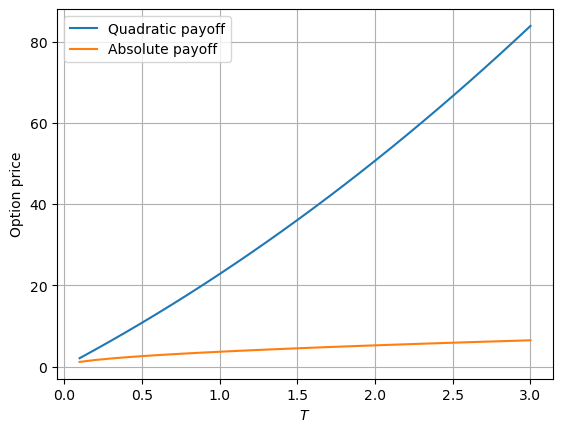

In [17]:
T_grid = np.linspace(0.1, 3, 30)

V_quad_T = [quadratic_analytic(S0, K, r, sigma, t) for t in T_grid]
V_abs_T  = [absolute_NI(S0, K, r, sigma, t) for t in T_grid]
plt.plot(T_grid, V_quad_T, label="Quadratic payoff")
plt.plot(T_grid, V_abs_T, label="Absolute payoff")
plt.xlabel("$T$")
plt.ylabel("Option price")
plt.legend()
plt.grid()
plt.savefig('report/Plots/7.pdf', bbox_inches='tight', dpi=1000)
plt.show()


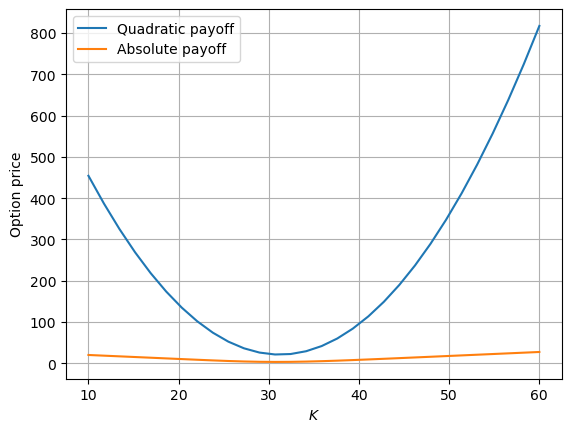

In [18]:
K_grid = np.linspace(10, 60, 30)

V_quad_K = [quadratic_analytic(S0, k, r, sigma, T) for k in K_grid]
V_abs_K  = [absolute_NI(S0, k, r, sigma, T) for k in K_grid]

plt.plot(K_grid, V_quad_K, label="Quadratic payoff")
plt.plot(K_grid, V_abs_K, label="Absolute payoff")
plt.xlabel("$K$")
plt.ylabel("Option price")
plt.legend()
plt.grid()
plt.savefig('report/Plots/8.pdf', bbox_inches='tight', dpi=1000)
plt.show()

In [19]:
S_grid = np.linspace(1, 80, 400)
times = [0.0, T/2, T]
def payoff_absolute(S, K):
    return np.abs(S - K)

def payoff_quadratic(S, K):
    return (S - K)**2

def payoff_call(S, K):
    return np.maximum(S - K, 0)

def call_price(S, K, r, sigma, tau):
    if tau == 0:
        return payoff_call(S, K)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*tau) / (sigma*np.sqrt(tau))
    d2 = d1 - sigma*np.sqrt(tau)
    return S*norm.cdf(d1) - K*np.exp(-r*tau)*norm.cdf(d2)

def quadratic_price(S, K, r, sigma, tau):
    return np.exp(-r*tau)*(S**2*np.exp(sigma**2*tau) - 2*K*S + K**2)

def absolute_price(S, K, r, sigma, tau, L=6, N=2000):
    if tau == 0:
        return payoff_absolute(S, K)
    u = np.linspace(-L, L, N)
    du = u[1] - u[0]
    ST = S*np.exp((r - 0.5*sigma**2)*tau + sigma*np.sqrt(tau)*u)
    return np.exp(-r*tau)*np.sum(np.abs(ST-K)*norm.pdf(u))*du

def delta_call(S, K, r, sigma, tau):
    if tau == 0:
        return np.where(S > K, 1, 0)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*tau) / (sigma*np.sqrt(tau))
    return norm.cdf(d1)

def delta_quadratic(S, K, sigma, tau):
    return 2*S*np.exp(sigma**2*tau) - 2*K

def delta_absolute(S, K):
    return np.where(S > K, 1, -1)

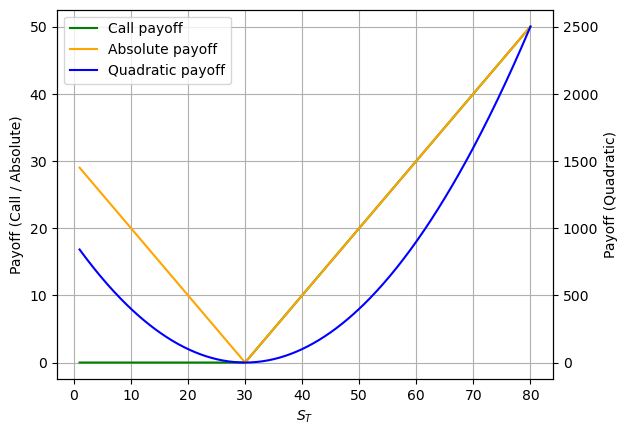

In [20]:
fig, ax1 = plt.subplots()

# Left axis: call + absolute
ax1.plot(S_grid, payoff_call(S_grid, K), label="Call payoff", color="green" )
ax1.plot(S_grid, payoff_absolute(S_grid, K), label="Absolute payoff", color="orange")
ax1.set_xlabel("$S_T$")
ax1.set_ylabel("Payoff (Call / Absolute)")
ax1.grid(True)

# Right axis: quadratic
ax2 = ax1.twinx()
ax2.plot(S_grid, payoff_quadratic(S_grid, K), label="Quadratic payoff", color="blue")
ax2.set_ylabel("Payoff (Quadratic)")

# Legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.savefig('report/Plots/9.pdf', bbox_inches='tight', dpi=1000)
plt.show()

In [21]:
times = [0.0, T/2, T]
labels = [r"$t=0$", r"$t=T/2$", r"$t=T$"]

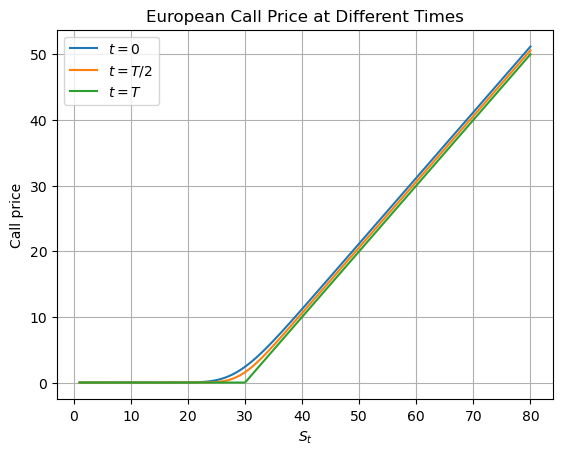

In [22]:
fig, ax = plt.subplots()

for t, lab in zip(times, labels):
    tau = T - t
    ax.plot(
        S_grid,
        [call_price(S, K, r, sigma, tau) for S in S_grid],
        label=lab
    )

ax.set_xlabel(r"$S_t$")
ax.set_ylabel("Call price")
ax.set_title("European Call Price at Different Times")
ax.legend()
ax.grid(True)

plt.savefig("report/Plots/call_time.pdf", bbox_inches="tight", dpi=1000)
plt.show()

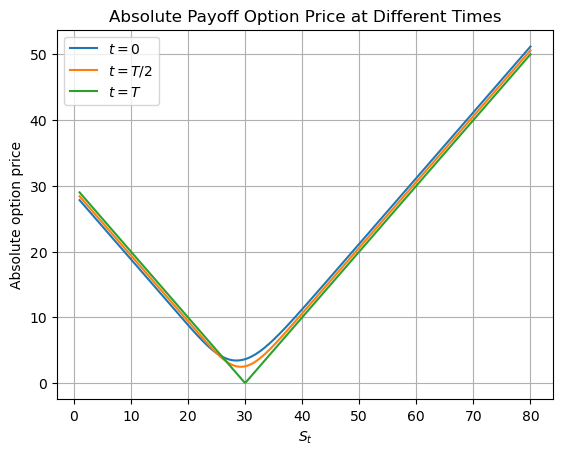

In [23]:
fig, ax = plt.subplots()

for t, lab in zip(times, labels):
    tau = T - t
    ax.plot(
        S_grid,
        [absolute_price(S, K, r, sigma, tau) for S in S_grid],
        label=lab
    )

ax.set_xlabel(r"$S_t$")
ax.set_ylabel("Absolute option price")
ax.set_title("Absolute Payoff Option Price at Different Times")
ax.legend()
ax.grid(True)

plt.savefig("report/Plots/absolute_time.pdf", bbox_inches="tight", dpi=1000)
plt.show()

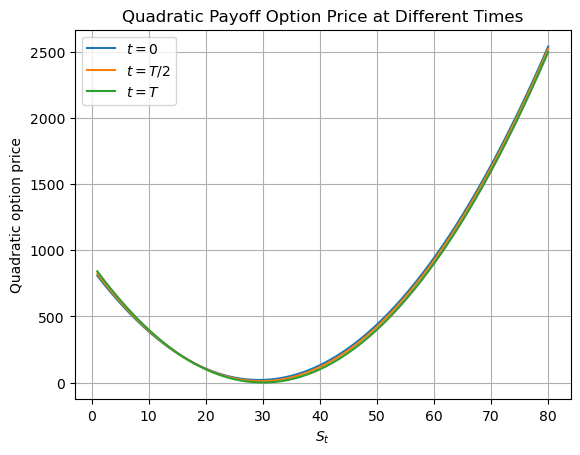

In [24]:
fig, ax = plt.subplots()

for t, lab in zip(times, labels):
    tau = T - t
    ax.plot(
        S_grid,
        [quadratic_price(S, K, r, sigma, tau) for S in S_grid],
        label=lab
    )

ax.set_xlabel(r"$S_t$")
ax.set_ylabel("Quadratic option price")
ax.set_title("Quadratic Payoff Option Price at Different Times")
ax.legend()
ax.grid(True)

plt.savefig("report/Plots/quadratic_time.pdf", bbox_inches="tight", dpi=1000)
plt.show()

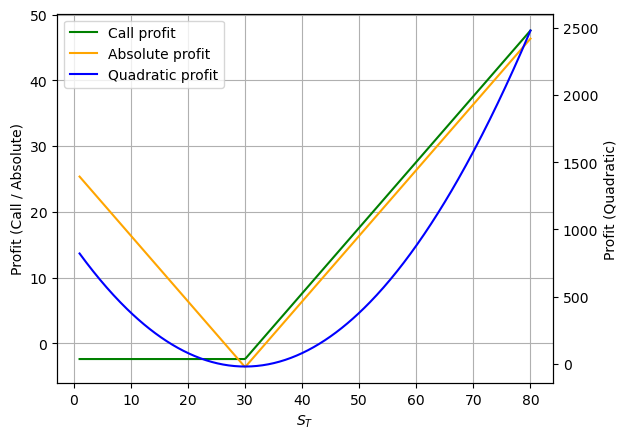

In [25]:
V0_call = call_price(S0, K, r, sigma, T)
V0_abs  = absolute_price(S0, K, r, sigma, T)
V0_quad = quadratic_price(S0, K, r, sigma, T)
fig, ax1 = plt.subplots()

ax1.plot(S_grid, payoff_call(S_grid, K) - V0_call,
         label="Call profit", color="green")
ax1.plot(S_grid, payoff_absolute(S_grid, K) - V0_abs,
         label="Absolute profit", color="orange")
ax1.set_xlabel("$S_T$")
ax1.set_ylabel("Profit (Call / Absolute)")
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(S_grid, payoff_quadratic(S_grid, K) - V0_quad,
         label="Quadratic profit", color="blue")
ax2.set_ylabel("Profit (Quadratic)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.savefig('report/Plots/10.pdf', bbox_inches='tight', dpi=1000)
plt.show()

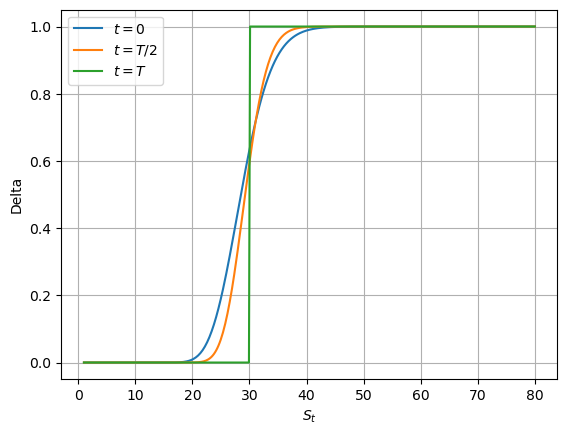

In [26]:
plt.figure()
for t, lab in zip(times, labels):
    tau = T - t
    plt.plot(S_grid,
             delta_call(S_grid, K, r, sigma, tau),
             label=lab)

plt.xlabel(r"$S_t$")
plt.ylabel("Delta")
plt.legend()
plt.grid(True)
plt.savefig('report/Plots/11.pdf', bbox_inches='tight', dpi=1000)
plt.show()

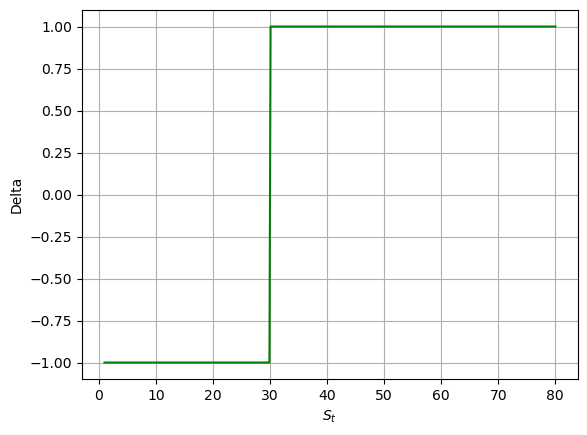

In [27]:
plt.figure()
plt.plot(S_grid,
         delta_absolute(S_grid, K),
         label="Delta", color="green")

plt.xlabel(r"$S_t$")
plt.ylabel("Delta")
plt.grid(True)
plt.savefig('report/Plots/12.pdf', bbox_inches='tight', dpi=1000)
plt.show()

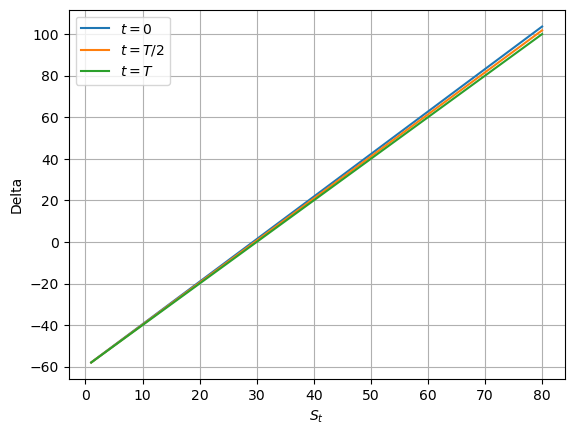

In [28]:
plt.figure()
for t, lab in zip(times, labels):
    tau = T - t
    plt.plot(S_grid,
             delta_quadratic(S_grid, K, sigma, tau),
             label=lab)

plt.xlabel(r"$S_t$")
plt.ylabel("Delta")
plt.legend()
plt.grid(True)
plt.savefig('report/Plots/13.pdf', bbox_inches='tight', dpi=1000)
plt.show()

In [29]:
def simulate_gbm(S0, r, sigma, T, N, seed=42):
    np.random.seed(seed)
    dt = T / N
    Z = np.random.randn(N)
    S = np.zeros(N+1)
    S[0] = S0

    for i in range(N):
        S[i+1] = S[i] * np.exp((r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z[i])

    return S

In [30]:
def replicate(S_path, delta_func, K, r, sigma, T):
    N = len(S_path) - 1
    dt = T / N

    V = np.zeros(N+1)
    Delta = np.zeros(N)

    # Initial portfolio value = theoretical price at t=0
    # For simplicity, set V0 = payoff at maturity discounted
    # (acceptable for Q3.1 demonstration)
    V[0] = 0.0

    for i in range(N):
        tau = T - i*dt
        Delta[i] = delta_func(S_path[i], K, sigma, tau)

        V[i+1] = (
            Delta[i] * S_path[i+1]
            + (V[i] - Delta[i] * S_path[i]) * np.exp(r*dt)
        )

    return V, Delta

In [31]:
# Parameters
S0 = 30
K = 30
r = 0.04
sigma = 0.15
T = 1
N = 252  # daily hedging

# Simulate underlying
S_path = simulate_gbm(S0, r, sigma, T, N)

# Replicate quadratic payoff
V_quad, Delta_quad = replicate(
    S_path,
    delta_quadratic,
    K, r, sigma, T
)

# Replicate absolute payoff
V_abs, Delta_abs = replicate(
    S_path,
    lambda S, K, sigma, tau: delta_absolute(S, K),
    K, r, sigma, T
)

In [32]:
V_quad

array([  0.        ,   0.19088672,   0.12352413,   0.41285608,
         1.26942303,   1.07167157,   0.88381823,   2.06850374,
         2.86096117,   2.30324049,   2.8922429 ,   2.33458048,
         1.81497255,   2.05781291,   0.03018243,  -1.2031078 ,
        -1.44105773,  -1.77194203,  -1.7224393 ,  -1.91553704,
        -2.00887964,  -2.23581553,  -2.25354361,  -2.25139125,
        -2.32430022,  -2.231321  ,  -2.25850659,  -1.9882289 ,
        -2.1393739 ,  -1.92821058,  -1.79889567,  -1.50910868,
        -2.56272149,  -2.55773894,  -2.24371667,  -2.61554879,
        -2.21181783,  -2.31619928,  -1.38468265,  -0.38782277,
        -0.5666689 ,  -1.23205154,  -1.36650903,  -1.27268955,
        -1.0295038 ,   0.203311  ,   0.94721171,   1.46789672,
         0.22214044,  -0.13259714,   1.62203364,   1.23146198,
         1.69153043,   2.52683228,   1.72950463,   0.4546071 ,
        -0.57708848,   0.25477   ,   0.59857297,   0.22740441,
        -0.83892026,  -0.3716182 ,  -0.17580113,   0.98

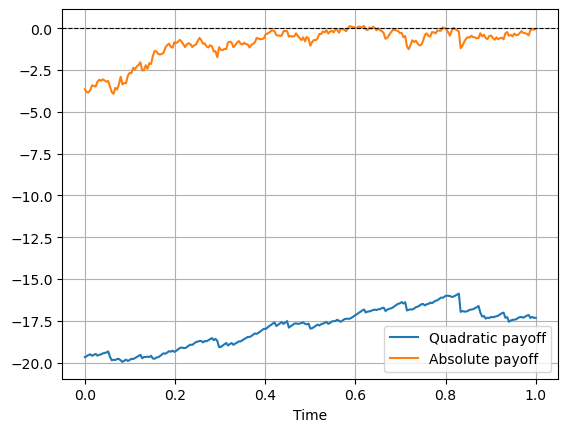

In [37]:
# Time grid
time_grid = np.linspace(0, T, N+1)

# Theoretical prices along the path (needed for error)
V_theo_quad = [quadratic_price(S_path[i], K, r, sigma, T - i*T/N)
               for i in range(N+1)]

V_theo_abs = [absolute_price(S_path[i], K, r, sigma, T - i*T/N)
              for i in range(N+1)]

# Replication errors
error_quad = V_quad - V_theo_quad
error_abs = V_abs - V_theo_abs

# Plot
plt.figure()
plt.plot(time_grid, error_quad, label="Quadratic payoff")
plt.plot(time_grid, error_abs, label="Absolute payoff")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Time")
plt.legend()
plt.grid(True)
plt.savefig('report/Plots/14.pdf', bbox_inches='tight', dpi=1000)
plt.show()

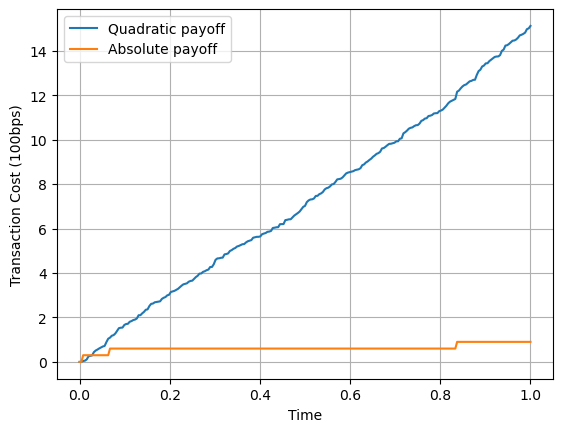

In [41]:
c = 0.005  # 50 bps

# Compute cumulative costs
cost_quad = np.zeros(N+1)
cost_abs = np.zeros(N+1)

for i in range(1, N):
    cost_quad[i+1] = (
        cost_quad[i]
        + c * abs(Delta_quad[i] - Delta_quad[i-1]) * S_path[i]
    )
    cost_abs[i+1] = (
        cost_abs[i]
        + c * abs(Delta_abs[i] - Delta_abs[i-1]) * S_path[i]
    )

# Plot
plt.figure()
plt.plot(time_grid, cost_quad, label="Quadratic payoff")
plt.plot(time_grid, cost_abs, label="Absolute payoff")
plt.xlabel("Time")
plt.ylabel("Transaction Cost (100bps)")
plt.legend()
plt.grid(True)
plt.savefig('report/Plots/15.pdf', bbox_inches='tight', dpi=1000)
plt.show()